# Importing libraries

In [14]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

# Save model
import joblib

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [13]:
# load dataset
df = pd.read_csv("credit_risk_data.csv")
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [5]:
df.shape

(50000, 27)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  object 
 1   Customer_ID               50000 non-null  object 
 2   Month                     50000 non-null  object 
 3   Name                      44985 non-null  object 
 4   Age                       50000 non-null  object 
 5   SSN                       50000 non-null  object 
 6   Occupation                50000 non-null  object 
 7   Annual_Income             50000 non-null  object 
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  object 
 13  Type_of_Loan              44296 non-null  object 
 14  Delay_

In [7]:
df.isnull().sum()

ID                             0
Customer_ID                    0
Month                          0
Name                        5015
Age                            0
SSN                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       7498
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                5704
Delay_from_due_date            0
Num_of_Delayed_Payment      3498
Changed_Credit_Limit           0
Num_Credit_Inquiries        1035
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age          4470
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     2271
Payment_Behaviour              0
Monthly_Balance              562
dtype: int64

In [9]:
df.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,42502.000000,50000.000000,50000.000000,50000.000000,50000.000000,48965.000000,50000.000000,50000.000000
mean,4182.004291,16.838260,22.921480,68.772640,21.052640,30.080200,32.279581,1491.304305
std,3174.109304,116.396848,129.314804,451.602363,14.860397,196.984121,5.106238,8595.647887
min,303.645417,-1.000000,0.000000,1.000000,-5.000000,0.000000,20.509652,0.000000
25%,1625.188333,3.000000,4.000000,8.000000,10.000000,4.000000,28.061040,32.222388
50%,3086.305000,6.000000,5.000000,13.000000,18.000000,7.000000,32.280390,74.733349
75%,5934.189094,7.000000,7.000000,20.000000,28.000000,10.000000,36.468591,176.157491
max,15204.633333,1798.000000,1499.000000,5799.000000,67.000000,2593.000000,48.540663,82398.000000


In [10]:
print(df.columns.tolist())

['Customer_ID', 'Age', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance']


In [16]:
print("Dataset Shape:", df.shape)

Dataset Shape: (32581, 12)


In [17]:
# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 165


loan_status
0    25473
1     7108
Name: count, dtype: int64


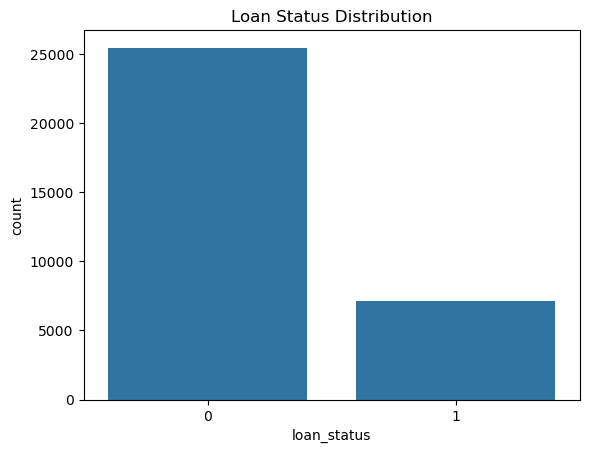

In [18]:
# Check target distribution

print(df["loan_status"].value_counts())

sns.countplot(data=df, x="loan_status")
plt.title("Loan Status Distribution")
plt.show()

In [19]:
# Remove duplicate rows

df.drop_duplicates(inplace=True)

print("Dataset Shape:", df.shape)

Dataset Shape: (32416, 12)


Handle missing values

In [20]:
# Check unusual values in important columns

print("Age above 100:", (df["person_age"] > 100).sum())

print("Income less than or equal to 0:",
      (df["person_income"] <= 0).sum())

print("Negative employment length:",
      (df["person_emp_length"] < 0).sum())

print("Negative loan amount:",
      (df["loan_amnt"] <= 0).sum())

Age above 100: 5
Income less than or equal to 0: 0
Negative employment length: 0
Negative loan amount: 0


In [21]:
# Remove records with unrealistic age and invalid financial values

df = df[
    (df["person_age"] <= 100) &
    (df["person_age"] >= 18) &
    (df["person_income"] > 0) &
    (df["person_emp_length"] >= 0) &
    (df["loan_amnt"] > 0)
]

print("Shape after cleaning:", df.shape)

Shape after cleaning: (31524, 12)


# Exploratory Data Analysis

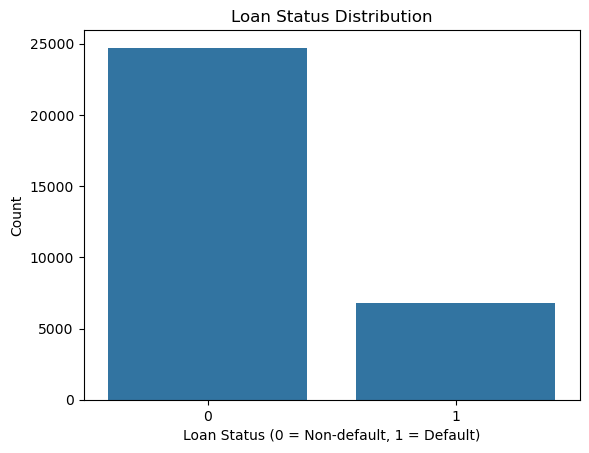

In [22]:
# Visualize loan status

sns.countplot(data=df, x="loan_status")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Count")

plt.show()

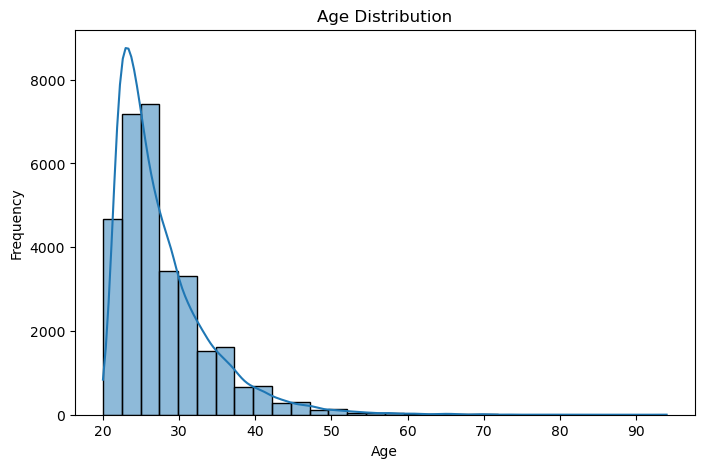

In [23]:
# Distribution of applicant age

plt.figure(figsize=(8, 5))

sns.histplot(df["person_age"], bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

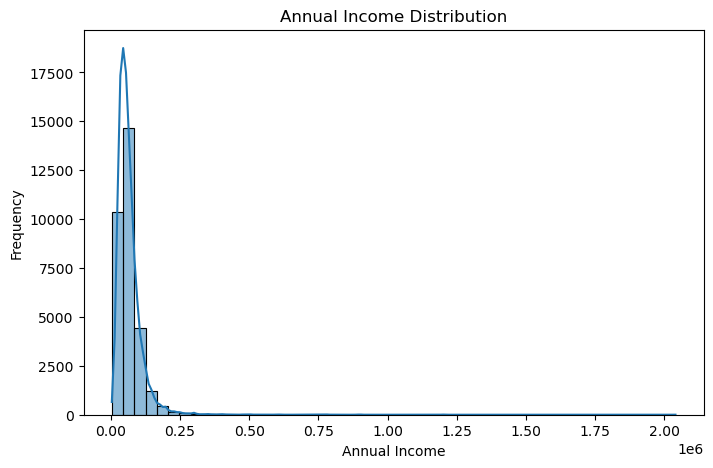

In [24]:
# Distribution of applicant income

plt.figure(figsize=(8, 5))

sns.histplot(df["person_income"], bins=50, kde=True)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")

plt.show()

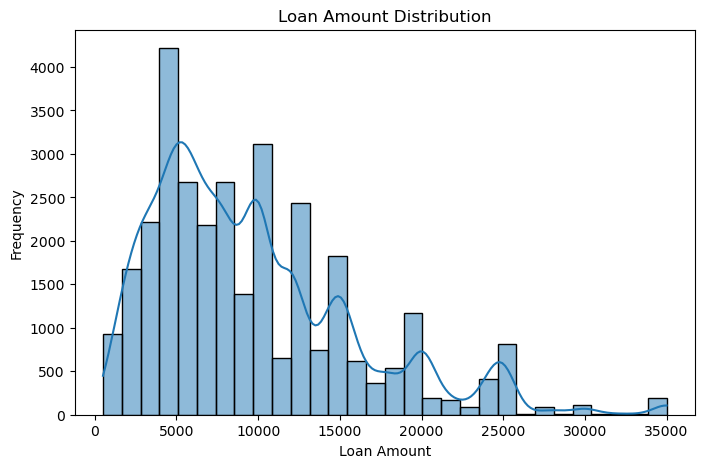

In [25]:
# Distribution of loan amount

plt.figure(figsize=(8, 5))

sns.histplot(df["loan_amnt"], bins=30, kde=True)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")

plt.show()

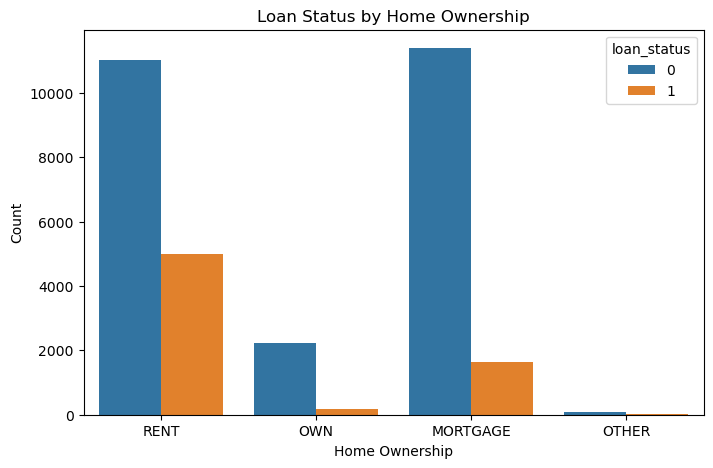

In [26]:
# Compare loan defaults by home ownership

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="person_home_ownership", hue="loan_status")

plt.title("Loan Status by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Count")

plt.show()

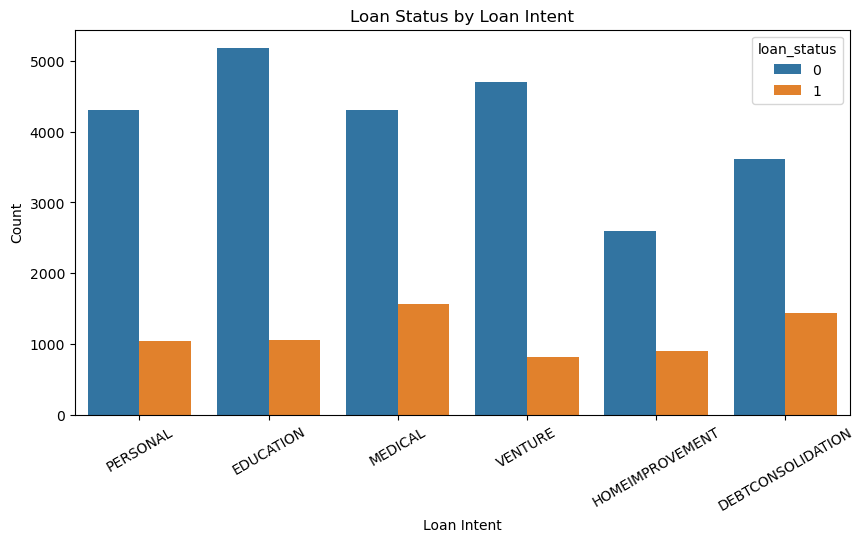

In [27]:
# Compare loan defaults by loan purpose

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="loan_intent", hue="loan_status")

plt.title("Loan Status by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Count")

plt.xticks(rotation=30)

plt.show()

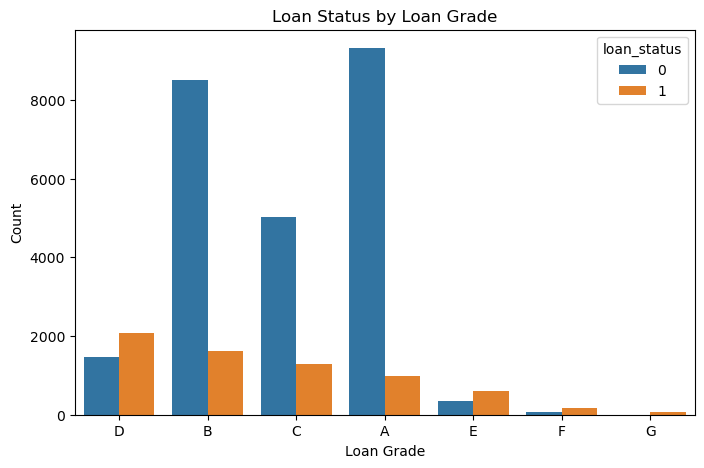

In [28]:
# Analyze loan status for different loan grades

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="loan_grade", hue="loan_status")

plt.title("Loan Status by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Count")

plt.show()

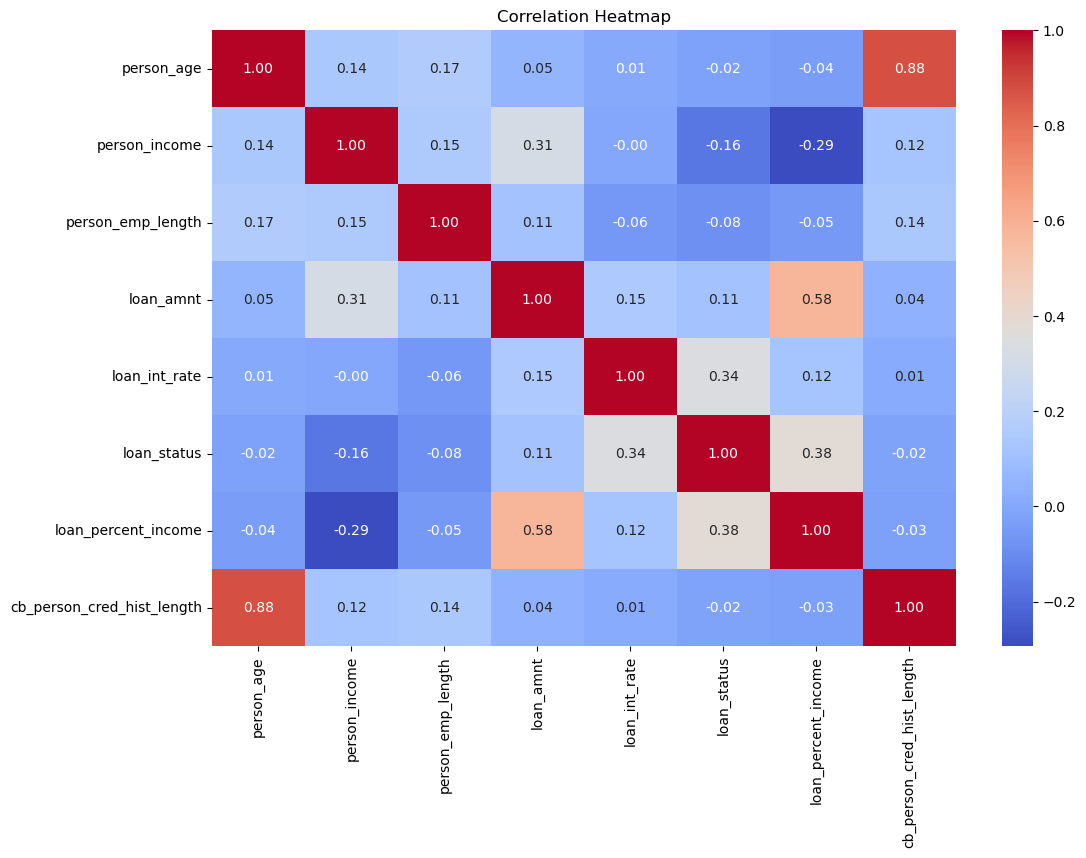

In [29]:
# Correlation heatmap
# Select numerical columns

numeric_df = df.select_dtypes(include=["int64", "float64"])

# Plot correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Feature Engineering

In [30]:
# Calculate loan burden relative to annual income

df["Loan_to_Income"] = df["loan_amnt"] / df["person_income"]

# Calculate employment experience relative to age

df["Employment_Age_Ratio"] = (
    df["person_emp_length"] / df["person_age"]
)

# Display updated dataset

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Loan_to_Income,Employment_Age_Ratio
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,0.593220,5.590909
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,0.104167,0.238095
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,0.572917,0.040000
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,0.534351,0.173913
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,0.643382,0.333333


In [31]:
# Separate independent and dependent variables

X = df.drop("loan_status", axis=1)

y = df["loan_status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (31524, 13)
Target Shape: (31524,)


In [32]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'Loan_to_Income', 'Employment_Age_Ratio']

Categorical Features:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


Split the dataset

In [33]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (25219, 13)
Testing Data: (6305, 13)


In [35]:
# Create numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Train Logistic Regression

In [36]:
# Create Logistic Regression pipeline

lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model

lr_model.fit(X_train, y_train)

# Make predictions

lr_pred = lr_model.predict(X_test)

# Predict probabilities

lr_prob = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


Train Decision Tree

In [38]:
# Create Decision Tree pipeline

dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model

dt_model.fit(X_train, y_train)

# Make predictions

dt_pred = dt_model.predict(X_test)

# Predict probabilities

dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


Train Random Forest

In [39]:
# Create Random Forest pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model

rf_model.fit(X_train, y_train)

# Make predictions

rf_pred = rf_model.predict(X_test)

# Predict probabilities

rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Training Completed!")

Random Forest Training Completed!


Compare model performance

In [40]:
# Create a function to evaluate models

def evaluate_model(model_name, y_test, y_pred, y_prob):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

In [41]:
# Compare all trained models

results = []

results.append(
    evaluate_model("Logistic Regression", y_test, lr_pred, lr_prob)
)

results.append(
    evaluate_model("Decision Tree", y_test, dt_pred, dt_prob)
)

results.append(
    evaluate_model("Random Forest", y_test, rf_pred, rf_prob)
)

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8265,0.5720,0.7812,0.6605,0.8817
1,Decision Tree,0.9066,0.8218,0.7247,0.7702,0.8997
2,Random Forest,0.9245,0.9171,0.7151,0.8036,0.9333


Visualize model comparison

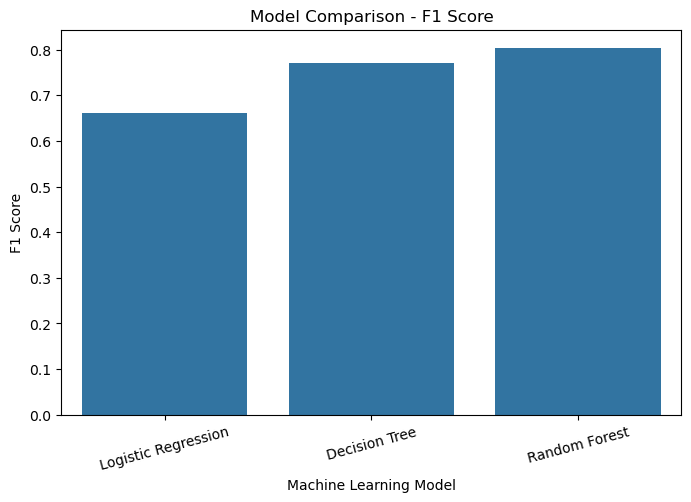

In [42]:
# Compare model performance using F1-score

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Model Comparison - F1 Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=15)
plt.show()

Confusion Matrix

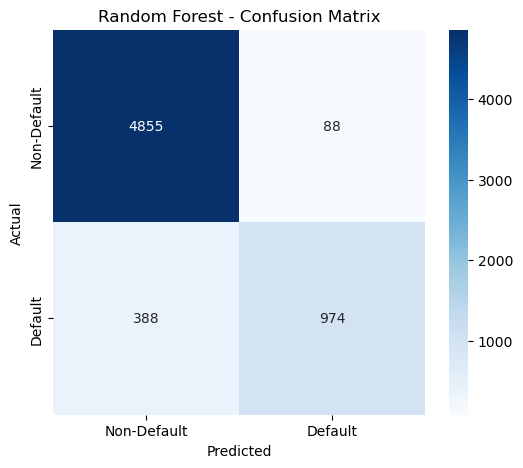

In [43]:
# Plot confusion matrix

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Default", "Default"],
    yticklabels=["Non-Default", "Default"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

ROC Curve

<Figure size 800x600 with 0 Axes>

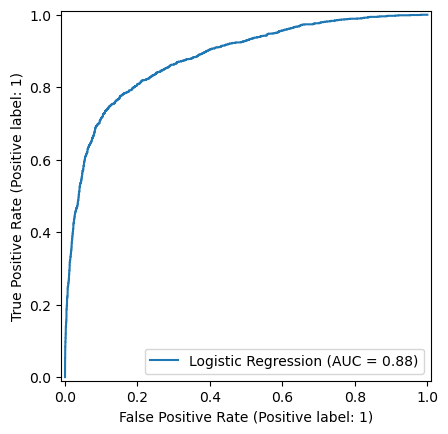

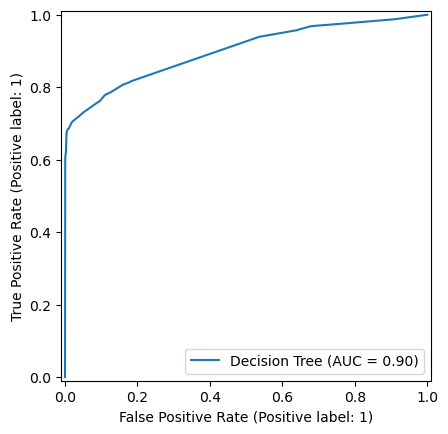

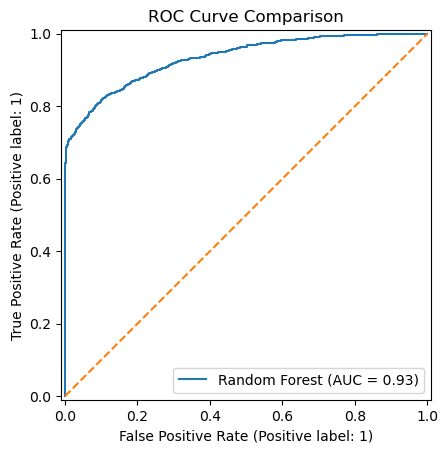

In [44]:
# Plot ROC curves for all three models

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test, lr_prob, name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test, dt_prob, name="Decision Tree"
)

RocCurveDisplay.from_predictions(
    y_test, rf_prob, name="Random Forest"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve Comparison")
plt.show()

Classification Report

In [45]:
# Detailed performance report for Random Forest

print(classification_report(
    y_test,
    rf_pred,
    target_names=["Non-Default", "Default"]
))

              precision    recall  f1-score   support

 Non-Default       0.93      0.98      0.95      4943
     Default       0.92      0.72      0.80      1362

    accuracy                           0.92      6305
   macro avg       0.92      0.85      0.88      6305
weighted avg       0.92      0.92      0.92      6305

